In [54]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [55]:
df = pd.read_csv("Stevens-2-1.csv")

In [56]:
df.head()

,Docket,Term,Circuit,Issue,Petitioner,Respondent,LowerCourt,Unconst,Reverse
0,93-1408,1994,2nd,EconomicActivity,BUSINESS,BUSINESS,liberal,0,1
1,93-1577,1994,9th,EconomicActivity,BUSINESS,BUSINESS,liberal,0,1
2,93-1612,1994,5th,EconomicActivity,BUSINESS,BUSINESS,liberal,0,1
3,94-623,1994,1st,EconomicActivity,BUSINESS,BUSINESS,conser,0,1
4,94-1175,1995,7th,JudicialPower,BUSINESS,BUSINESS,conser,0,1


In [57]:
X = df.drop(['Docket','Term','Reverse'], axis = 1) # axis = 1 drop operation based on column, axis =0 drop operation based on row
print(X)

    Circuit              Issue Petitioner Respondent LowerCourt  Unconst
0       2nd   EconomicActivity   BUSINESS   BUSINESS    liberal        0
1       9th   EconomicActivity   BUSINESS   BUSINESS    liberal        0
2       5th   EconomicActivity   BUSINESS   BUSINESS    liberal        0
3       1st   EconomicActivity   BUSINESS   BUSINESS     conser        0
4       7th      JudicialPower   BUSINESS   BUSINESS     conser        0
..      ...                ...        ...        ...        ...      ...
561     6th  CriminalProcedure      OTHER         US     conser        0
562     5th  CriminalProcedure      OTHER         US    liberal        0
563     9th  CriminalProcedure      OTHER         US     conser        1
564      DC        CivilRights      STATE         US     conser        0
565     9th        CivilRights      STATE         US    liberal        0

[566 rows x 6 columns]


In [58]:
y = df['Reverse'] #y is the dependent variable

In [59]:
X = pd.get_dummies(X)
print(X.head())

   Unconst  Circuit_10th  Circuit_11th  Circuit_1st  Circuit_2nd  Circuit_3rd  \
0        0         False         False        False         True        False   
1        0         False         False        False        False        False   
2        0         False         False        False        False        False   
3        0         False         False         True        False        False   
4        0         False         False        False        False        False   

   Circuit_4th  Circuit_5th  Circuit_6th  Circuit_7th  ...  \
0        False        False        False        False  ...   
1        False        False        False        False  ...   
2        False         True        False        False  ...   
3        False        False        False        False  ...   
4        False        False        False         True  ...   

   Respondent_EMPLOYEE  Respondent_EMPLOYER  Respondent_GOVERNMENT.OFFICIAL  \
0                False                False                  

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [61]:
dt_100 = DecisionTreeClassifier(min_samples_leaf=100, random_state=42)
dt_100.fit(X_train, y_train)

DecisionTreeClassifier(min_samples_leaf=100, random_state=42)

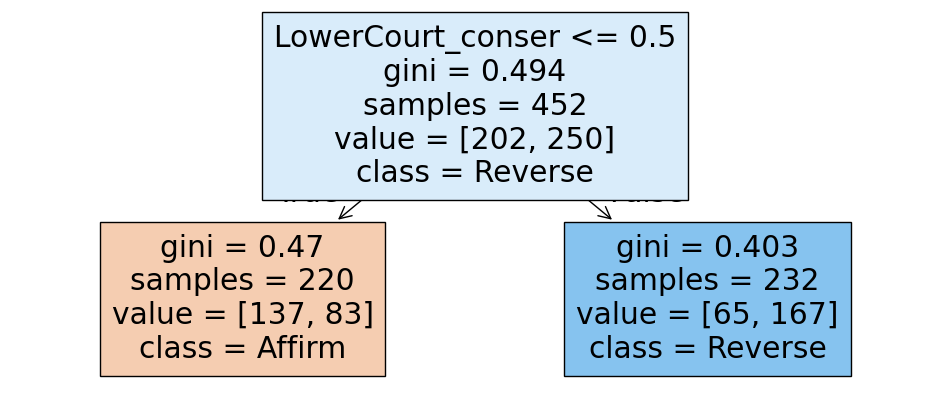

In [62]:
plt.figure(figsize=(12,5))
plot_tree(dt_100, filled=True, feature_names=X.columns, class_names=['Affirm', 'Reverse'])
plt.show()

In [63]:
dt_40 = DecisionTreeClassifier(min_samples_leaf=40, random_state=42)
dt_40.fit(X_train, y_train)

DecisionTreeClassifier(min_samples_leaf=40, random_state=42)

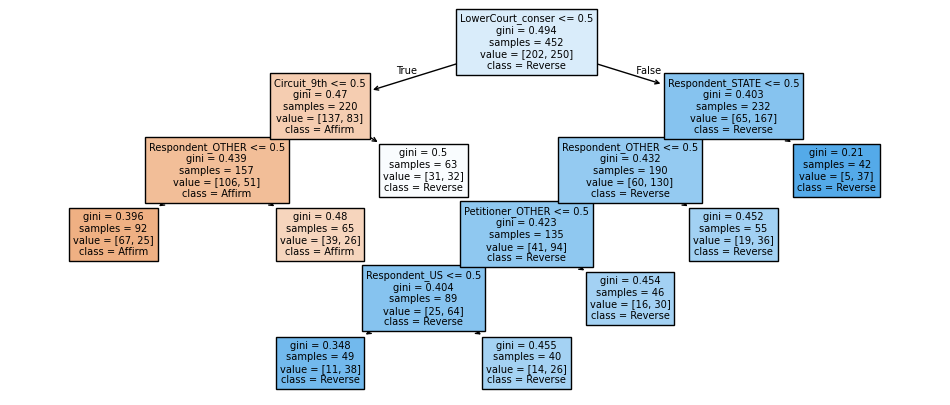

In [64]:
plt.figure(figsize=(12,5))
plot_tree(dt_40, filled=True, feature_names=X.columns, class_names=['Affirm', 'Reverse'])
plt.show()

In [65]:
dt_40.predict_proba(X_test)[:,1]

array([0.65      , 0.65      , 0.27173913, 0.65      , 0.88095238,
       0.4       , 0.65454545, 0.27173913, 0.50793651, 0.27173913,
       0.7755102 , 0.27173913, 0.4       , 0.7755102 , 0.4       ,
       0.27173913, 0.65454545, 0.88095238, 0.65      , 0.50793651,
       0.50793651, 0.7755102 , 0.7755102 , 0.4       , 0.88095238,
       0.50793651, 0.7755102 , 0.27173913, 0.27173913, 0.4       ,
       0.50793651, 0.50793651, 0.7755102 , 0.27173913, 0.65217391,
       0.65      , 0.7755102 , 0.7755102 , 0.7755102 , 0.4       ,
       0.65454545, 0.65454545, 0.27173913, 0.65454545, 0.50793651,
       0.65217391, 0.88095238, 0.50793651, 0.65454545, 0.27173913,
       0.27173913, 0.27173913, 0.65217391, 0.27173913, 0.27173913,
       0.50793651, 0.88095238, 0.88095238, 0.65217391, 0.50793651,
       0.7755102 , 0.50793651, 0.27173913, 0.4       , 0.27173913,
       0.65217391, 0.50793651, 0.65454545, 0.50793651, 0.7755102 ,
       0.4       , 0.50793651, 0.65      , 0.4       , 0.4    

In [66]:
y_pred_prob_test = dt_100.predict_proba(X_test)[:,1] # [:,1] => all rows, and second col gives prob of y =1